In [2]:
import anndata
import numpy as np
import seaborn as sb
import numpy as np
import warnings
import matplotlib.pyplot as plt
import anndata as ad
import scipy.sparse as sp
import pandas as pd
warnings.filterwarnings("ignore")

from genes2genes import Main
from genes2genes import ClusterUtils
from genes2genes import TimeSeriesPreprocessor
from genes2genes import PathwayAnalyser
from genes2genes import VisualUtils

In [3]:
import os
current_dir = os.getcwd()
print(current_dir)

/home/balawar/chlyu_NRBC_g2g_result


In [4]:
os.chdir('../')

In [5]:
input_dir = 'data_share_old/2021_NRBC_chlyu/NRBC_monocle_analysis/genes2genes/'
os.listdir(input_dir)

['YS_cds_metadata.csv',
 'FBM_cds_mtx.csv',
 'FL_cds_mtx.csv',
 'ABM_cds_metadata.csv',
 'ABM_cds_mtx.csv',
 'FL_cds_metadata.csv',
 'YS_cds_mtx.csv',
 'FBM_cds_metadata.csv']

In [6]:
expr_df = pd.read_csv(input_dir + 'YS_cds_mtx.csv', index_col=0)
expr_df=expr_df.T
meta_df = pd.read_csv(input_dir + 'YS_cds_metadata.csv', index_col=0)
sparse_matrix = sp.csr_matrix(expr_df.values)
YS_adata = ad.AnnData(X=sparse_matrix,  obs=meta_df,  var=pd.DataFrame(index=expr_df.columns) )
del expr_df
del sparse_matrix
del meta_df

In [7]:
expr_df = pd.read_csv(input_dir + 'FBM_cds_mtx.csv', index_col=0)
expr_df=expr_df.T
meta_df = pd.read_csv(input_dir + 'FBM_cds_metadata.csv', index_col=0)
meta_df = meta_df.loc[expr_df.index]
sparse_matrix = sp.csr_matrix(expr_df.values)
FBM_adata = ad.AnnData(X=sparse_matrix,  obs=meta_df,  var=pd.DataFrame(index=expr_df.columns) )
del expr_df
del sparse_matrix
del meta_df

In [8]:
print("Ref time range:", YS_adata.obs['Pseudotime'].min(), YS_adata.obs['Pseudotime'].max())
print("Query time range:", FBM_adata.obs['Pseudotime'].min(), FBM_adata.obs['Pseudotime'].max())

Ref time range: 0.0 34.3409649589075
Query time range: 0.0 64.6370062612976


In [9]:
YS_adata.obs['Pseudotime'] = TimeSeriesPreprocessor.Utils.minmax_normalise(np.asarray(YS_adata.obs['Pseudotime']))
FBM_adata.obs['Pseudotime'] = TimeSeriesPreprocessor.Utils.minmax_normalise(np.asarray(FBM_adata.obs['Pseudotime']))

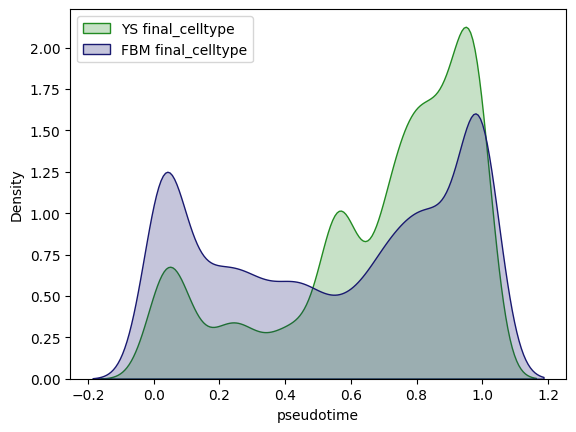

In [10]:
# Visualize the pseudotime distributions
sb.kdeplot(YS_adata.obs['Pseudotime'], fill=True, label='YS final_celltype', color='forestgreen') 
sb.kdeplot(FBM_adata.obs['Pseudotime'], fill=True, label='FBM final_celltype', color='midnightblue'); 
plt.xlabel('pseudotime'); plt.legend(); plt.show()

In [34]:
adata_ref=FBM_adata
adata_query=YS_adata

In [35]:
n_bins = 14

In [36]:
 adata_ref.obs.head()

,orig.ident,nCount_RNA,nFeature_RNA,age,sex,id,resource,S.Score,G2M.Score,Phase,tissue_stage,final_celltype,Ery_stage,source_celltype,sourceid,Pseudotime,annotation,time,bin_ids
FCAImmP7277559-AACTCCCGTGGTAACG,SeuratProject,72538.0,6817.0,17PCW,female,17PCW_F29,NaN,-0.274357,0.192338,G2M,FBM,BFUE/CFUE,early_Ery,FBM_BFUE/CFUE,FBM_17PCW_F29,0.023770,BFUE/CFUE,0.023770,1
FCAImmP7277559-CATGACACAGTTAACC,SeuratProject,70752.0,6246.0,17PCW,female,17PCW_F29,NaN,-0.179972,-0.040817,G1,FBM,ProE,early_Ery,FBM_ProE,FBM_17PCW_F29,0.045578,ProE,0.045578,1
FCAImmP7277559-AACGTTGCAGGTCCAC,SeuratProject,69027.0,5870.0,17PCW,female,17PCW_F29,NaN,-0.096947,-0.046029,G1,FBM,ProE,early_Ery,FBM_ProE,FBM_17PCW_F29,0.114839,ProE,0.114839,2
FCAImmP7277559-CCTACCACATATACCG,SeuratProject,68096.0,6188.0,17PCW,female,17PCW_F29,NaN,-0.083783,0.179956,G2M,FBM,ProE,early_Ery,FBM_ProE,FBM_17PCW_F29,0.072835,ProE,0.072835,1
FCAImmP7277559-TCTGAGAGTTATGTGC,SeuratProject,66220.0,5839.0,17PCW,female,17PCW_F29,NaN,-0.246266,0.240486,G2M,FBM,ProE,early_Ery,FBM_ProE,FBM_17PCW_F29,0.171420,ProE,0.171420,3


In [37]:
 adata_query.obs.head()

,orig.ident,nCount_RNA,nFeature_RNA,stage,orig.dataset,lanes,id,scDblFinder.class,scDblFinder.score,S.Score,...,Pre_celltype2,predicted.cluster,predicted.celltype,celltype,main_celltype,HBB_status,Pseudotime,annotation,time,bin_ids
Wang_et_al_AAACGGGGTTACAGAA_1-0,Wang,1791.939903,2061,CS10,Wang_et_al_Cell_Stem Cell_2021,Wang_CS10,CS10_Wang_CS10,singlet,0.023256,0.274412,...,lBas,2,eBas,eBas,Bas,negtive,0.049617,Bas,0.049617,1
Wang_et_al_AAAGATGAGAGATGAG_1-0,Wang,2580.867990,3896,CS10,Wang_et_al_Cell_Stem Cell_2021,Wang_CS10,CS10_Wang_CS10,singlet,0.000000,0.204622,...,eBas,7,EryP-CFC,EryP-CFC,EryP-CFC,negtive,0.025847,EryP-CFC,0.025847,1
Wang_et_al_AACACGTGTGATAAGT_1-0,Wang,2874.847870,4870,CS10,Wang_et_al_Cell_Stem Cell_2021,Wang_CS10,CS10_Wang_CS10,singlet,0.000172,0.104792,...,lBas,7,EryP-CFC,EryP-CFC,EryP-CFC,negtive,0.008575,EryP-CFC,0.008575,1
Wang_et_al_AACTCAGCACGGATAG_1-0,Wang,2075.413124,1188,CS10,Wang_et_al_Cell_Stem Cell_2021,Wang_CS10,CS10_Wang_CS10,singlet,0.083804,0.053183,...,eBas,7,EryP-CFC,EryP-CFC,EryP-CFC,negtive,0.042665,EryP-CFC,0.042665,1
Wang_et_al_AACTCCCCACGAAACG_1-0,Wang,1931.997946,3471,CS10,Wang_et_al_Cell_Stem Cell_2021,Wang_CS10,CS10_Wang_CS10,singlet,0.011628,0.262512,...,lBas,2,eBas,eBas,Bas,negtive,0.044655,Bas,0.044655,1


In [38]:
annotation_colname = 'annotation' 
# 直接使用你现有的 final_celltype 列
adata_ref.obs[annotation_colname] = adata_ref.obs['final_celltype'] 
adata_query.obs[annotation_colname] = adata_query.obs['main_celltype'] 

In [39]:
# 获取两个数据集中所有的唯一细胞类型
# 使用 union 可以确保如果 query 里有 ref 没有的细胞类型，也会被包含进去
all_celltypes = list(set(adata_ref.obs['final_celltype'].unique()) | set(adata_query.obs['main_celltype'].unique()))

# 根据细胞类型的数量从 seaborn colorblind 中提取对应的颜色
# 如果你觉得 colorblind 颜色不够多，可以换成 'tab20' 或 'Set1'
col = np.array(sb.color_palette('colorblind', n_colors=len(all_celltypes)))

# 自动构建字典
joint_cmap = {ct: col[i] for i, ct in enumerate(all_celltypes)}

# 打印出来检查一下
print(joint_cmap)

{'BFUE/CFUE': array([0.00392157, 0.45098039, 0.69803922]), 'ProE': array([0.87058824, 0.56078431, 0.01960784]), 'Poly': array([0.00784314, 0.61960784, 0.45098039]), 'Bas': array([0.83529412, 0.36862745, 0.        ]), 'EryP-CFC': array([0.8       , 0.47058824, 0.7372549 ]), 'Orth': array([0.79215686, 0.56862745, 0.38039216])}


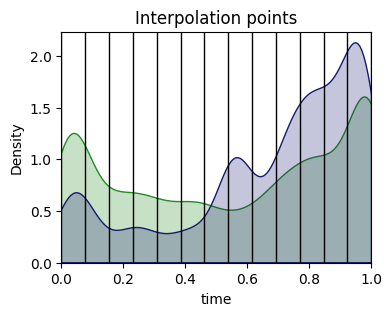

In [40]:
adata_ref.obs['time'] = adata_ref.obs['Pseudotime']
adata_query.obs['time'] = adata_query.obs['Pseudotime']
VisualUtils.plot_pseudotime_dists_with_interpolation_points(adata_ref, adata_query, n_bins)

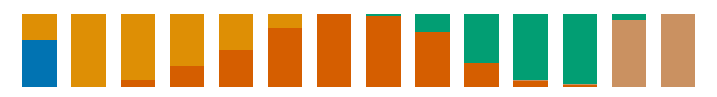

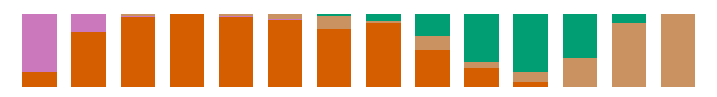

In [41]:
n_bins = 14
VisualUtils.plot_celltype_barplot(adata_ref, n_bins, annotation_colname, joint_cmap)
VisualUtils.plot_celltype_barplot(adata_query, n_bins, annotation_colname, joint_cmap)

In [42]:
maturation_genes = [
    "HBA1", "HBA2", "AHSP", "ALAS2", "FECH", 
    "HMBS", "SLC25A37", "SLC4A1", "ANK1", "EPB42",
    'GATA1','KLF1'
]

# 2. 取交集（非常重要：确保这些基因确实存在于你的 adata 矩阵中）
# 避免 G2G 报错 "Gene XXX not found in adata"
gene_list = list(
    set(maturation_genes) & 
    set(adata_ref.var_names) & 
    set(adata_query.var_names)
)
print(f"原始列表: {len(maturation_genes)} 个基因")
print(f"实际在数据集中找到: {len(gene_list)} 个基因")
print(f"用于比对的基因: {gene_list}")

原始列表: 12 个基因
实际在数据集中找到: 12 个基因
用于比对的基因: ['SLC4A1', 'SLC25A37', 'AHSP', 'FECH', 'EPB42', 'ANK1', 'HBA2', 'HBA1', 'ALAS2', 'GATA1', 'HMBS', 'KLF1']


In [43]:
aligner = Main.RefQueryAligner(adata_ref, adata_query, gene_list, n_bins) #
aligner.align_all_pairs() 

Genes2Genes (v0.2.0)
Dynamic programming alignment of gene pseudotime trajectories using a bayesian information-theoretic framework
Interpolator initialization completed
Aligner initialised to align trajectories of 6724 reference cells & 4844 query cells in terms of 12 genes
Running gene-level alignment: 🧬


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:02<00:00,  4.66it/s]

Alignment completed! ✅


Mean alignment similarity percentage (matched %): 
44.17 %


,Gene,alignment_similarity_percentage,opt_alignment_cost,l2fc,color,abs_l2fc
7,HBA1,0.0,72.073285,0.833539,red,0.833539
6,HBA2,0.037,71.981299,0.781655,red,0.781655
2,AHSP,0.0769,67.690521,0.571935,red,0.571935
5,ANK1,0.2727,59.30443,-0.639085,red,0.639085
9,GATA1,0.4737,36.168939,-0.49407,red,0.49407
1,SLC25A37,0.4737,48.099818,-0.29391,red,0.29391
3,FECH,0.4783,56.268967,-0.225019,red,0.225019
10,HMBS,0.5556,51.789515,-0.582433,green,0.582433
8,ALAS2,0.6471,35.013378,-0.079351,green,0.079351
11,KLF1,0.6842,39.291328,-0.4572,green,0.4572


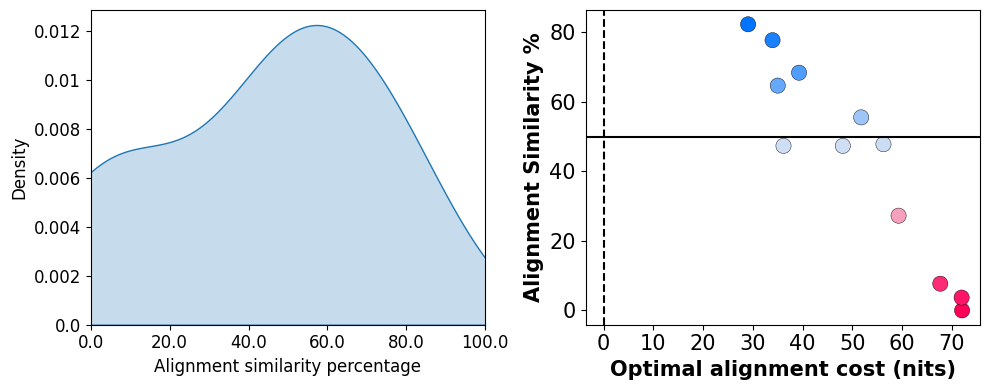

In [44]:
aligner.get_stat_df()

In [45]:
aligner.show_ordered_alignments()

In the order of the first match occurrence along pseudotime
Gene      Alignment
--------  ----------------------------
HBA1      IIIDIDIDIDIIIIIIIIDDDDDDDDDD
KLF1      MMWWWWMMMMMMMIIIIID
GATA1     MMMMMMMIIDDIDIDIDMM
EPB42     DDMMDDMMMMMMMMVVVV
SLC4A1    DDDMMMMMMMMMMMVVV
SLC25A37  DDDMMMDDMMIIIIIMMMM
ALAS2     DDDMMMIIMMMMMMMMI
HMBS      DDDDMMMMMMMMIIIIMM
ANK1      DDDDDDDDMMIIIIIIIIMMMM
HBA2      IIIDIDIIMIIIIIIIDDDDDDDDDDD
FECH      DDDDDDDDDMMIIIMMMVVVVVV
AHSP      IIIIIIIIIIIIMMDDDDDDDDDDDD


7         HBA1
11        KLF1
9        GATA1
4        EPB42
0       SLC4A1
1     SLC25A37
8        ALAS2
10        HMBS
5         ANK1
6         HBA2
3         FECH
2         AHSP
Name: genes, dtype: object

Average Alignment:  IDDDDMMMMMMIIIIDMMM (cell-level)
% similarity: 47.37


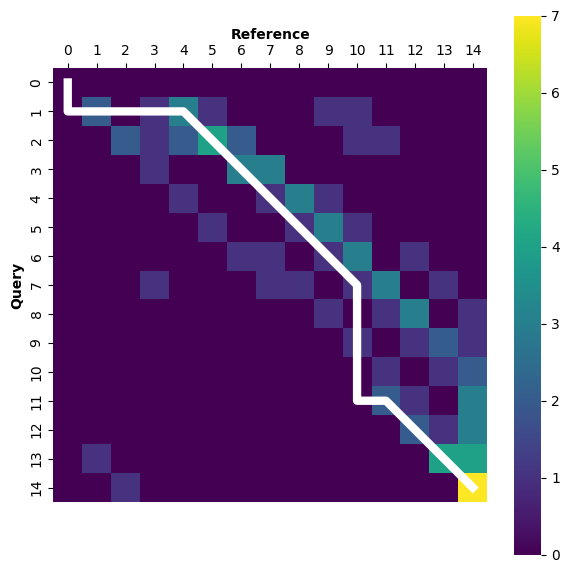

In [46]:
aligner.get_aggregate_alignment() 

Average Alignment:  IDDDDMMMMMMIIIIDMMM (cell-level)
% similarity: 47.37


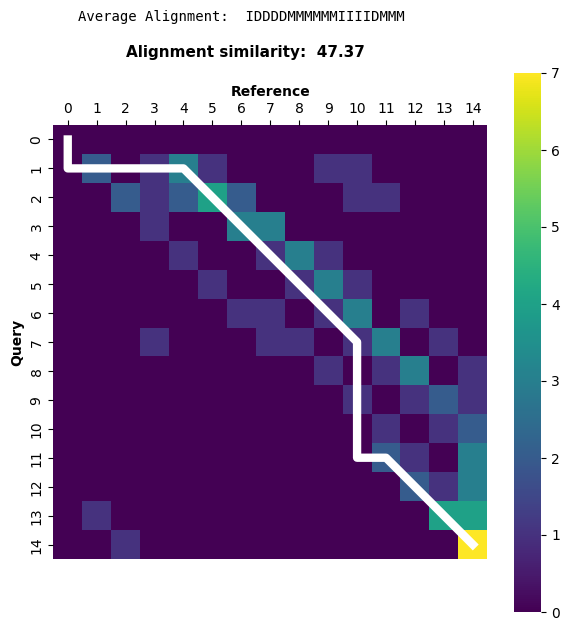

In [47]:
aligner.get_aggregate_alignment() 
# 获取生成的Figure
fig = plt.gcf()
# 添加Average Alignment
fig.text(0.4, 0.97,
    "Average Alignment:  IDDDDMMMMMMIIIIDMMM ",
    ha="center",
    va="top",
    fontsize=10,
    fontfamily="monospace",
    color="black"
)

# 添加相似度
fig.text(
    0.4, 0.92,
    "Alignment similarity:  47.37",
    ha="center",
    va="top",
    fontsize=11,
    fontweight="bold"
)

# 保存PDF
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_geneset_aggregate_alignment.pdf",format="pdf", bbox_inches="tight")

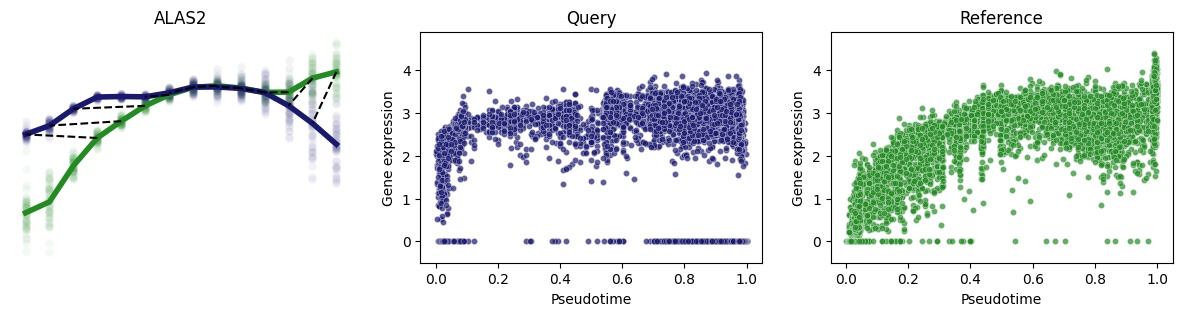

In [48]:

VisualUtils.plotTimeSeries('ALAS2', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_ALAS2_alignment.pdf",format="pdf", bbox_inches="tight")
# Visualise gene-level alignment in terms of only the cell-type composition 
# VisualUtils.visualize_gene_alignment(aligner.results_map['TNF'], adata_ref, adata_query, annotation_colname, cmap=joint_cmap)

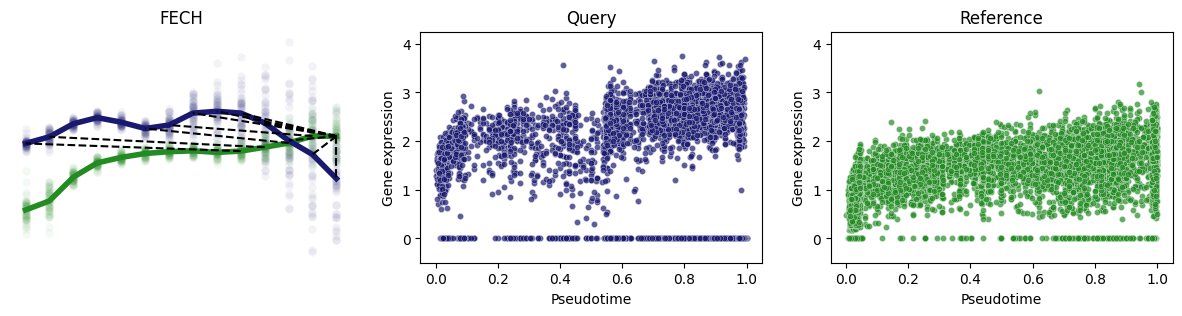

In [49]:
VisualUtils.plotTimeSeries('FECH', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_FECH_alignment.pdf",format="pdf", bbox_inches="tight")

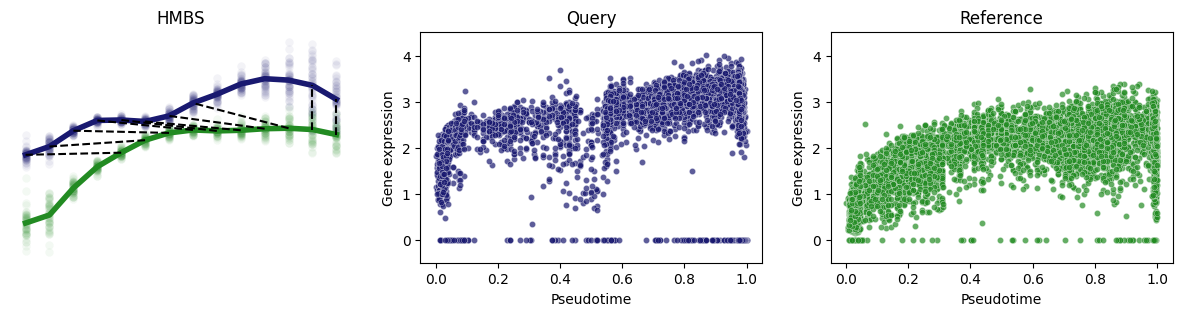

In [50]:
VisualUtils.plotTimeSeries('HMBS', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_HMBS_alignment.pdf",format="pdf", bbox_inches="tight")

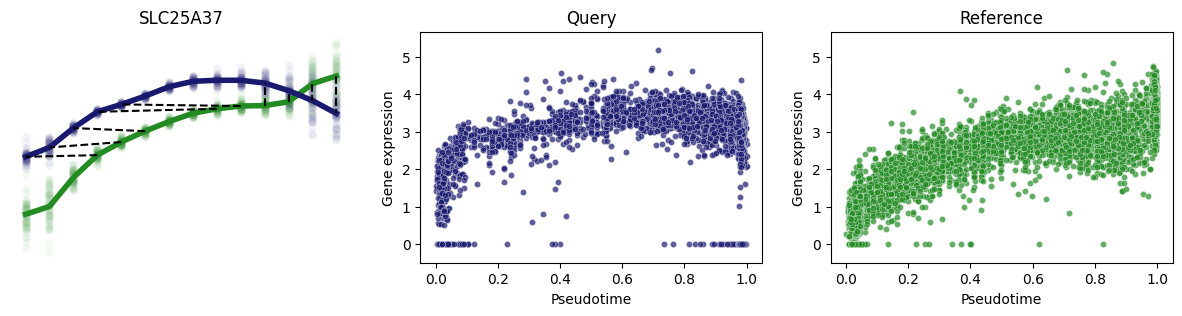

In [51]:
VisualUtils.plotTimeSeries('SLC25A37', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_SLC25A37_alignment.pdf",format="pdf", bbox_inches="tight")

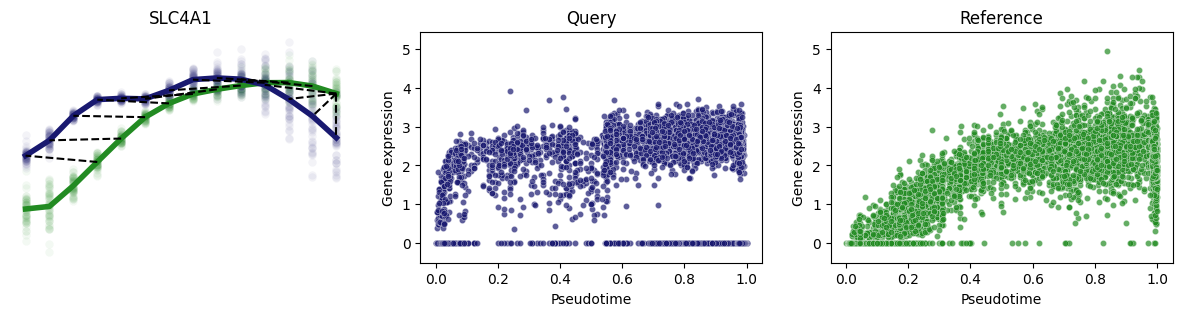

In [52]:
VisualUtils.plotTimeSeries('SLC4A1', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_SLC4A1_alignment.pdf",format="pdf", bbox_inches="tight")

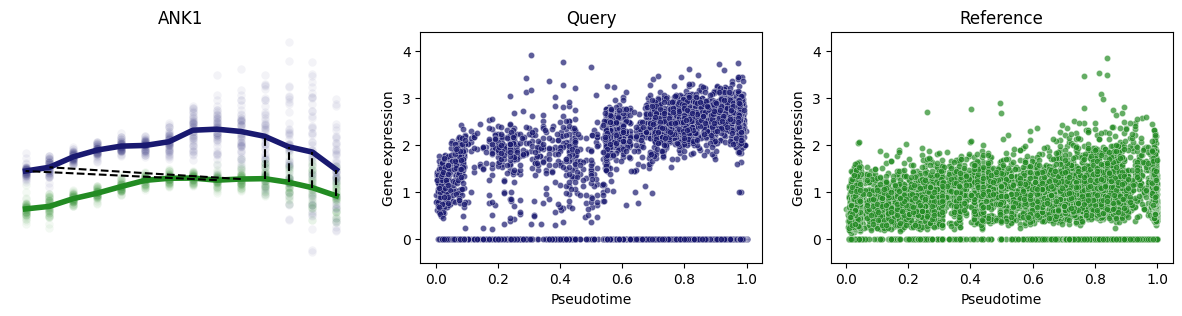

In [53]:
VisualUtils.plotTimeSeries('ANK1', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_ANK1_alignment.pdf",format="pdf", bbox_inches="tight")

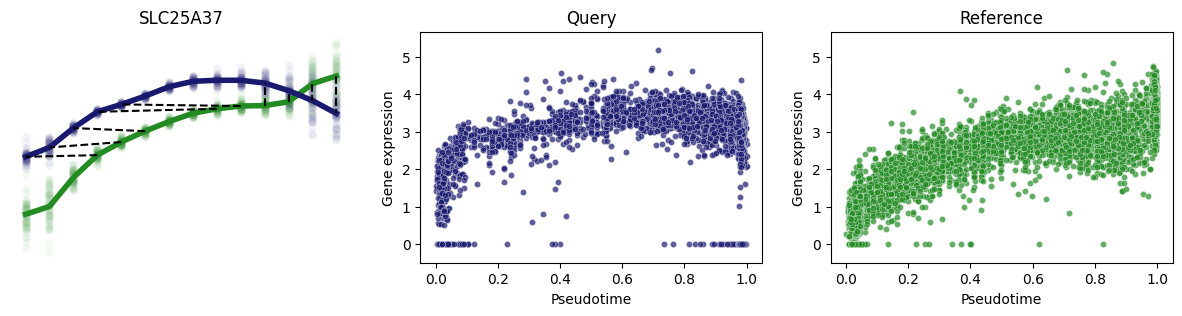

In [54]:
VisualUtils.plotTimeSeries('SLC25A37', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_SLC25A37_alignment.pdf",format="pdf", bbox_inches="tight")

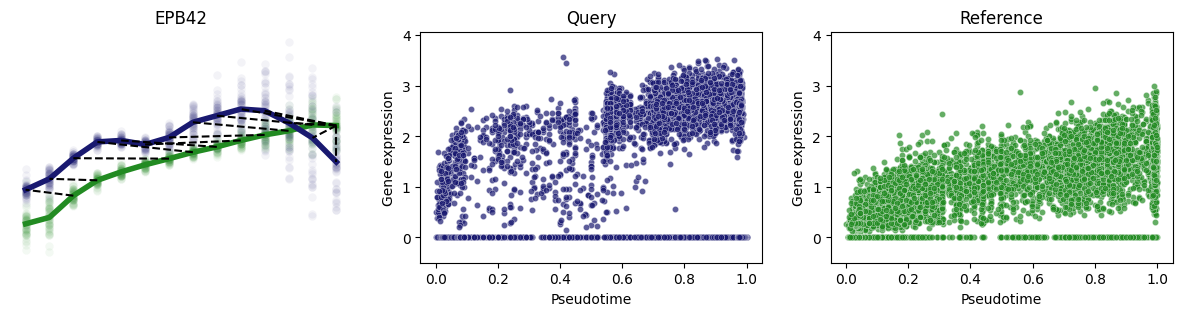

In [55]:
VisualUtils.plotTimeSeries('EPB42', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_EPB42_alignment.pdf",format="pdf", bbox_inches="tight")
# Visualise gene-level alignment in terms of only the cell-type composition 
# VisualUtils.visualize_gene_alignment(aligner.results_map['TNF'], adata_ref, adata_query, annotation_colname, cmap=joint_cmap)

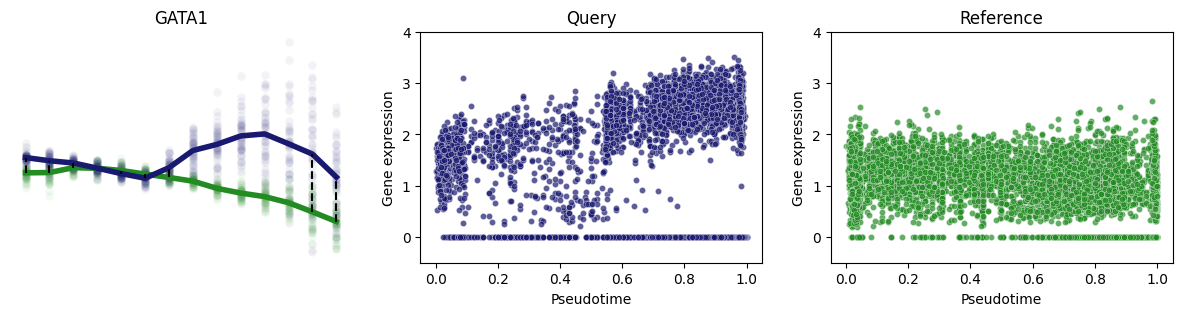

In [56]:
VisualUtils.plotTimeSeries('GATA1', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_GATA1_alignment.pdf",format="pdf", bbox_inches="tight")

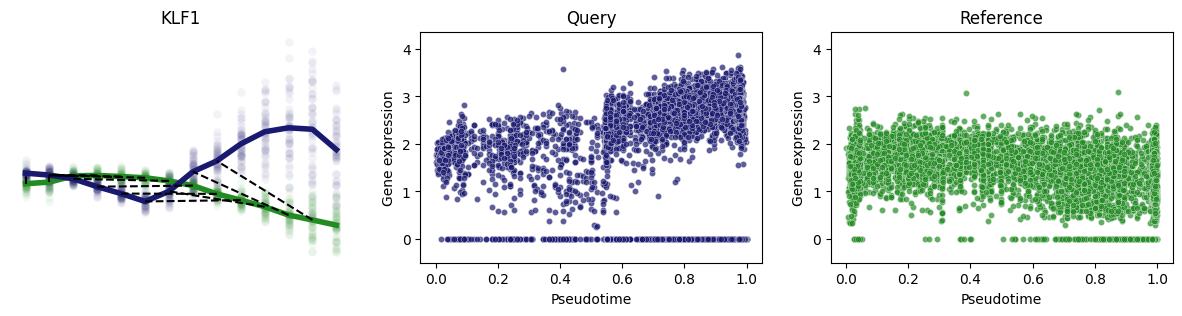

In [57]:
VisualUtils.plotTimeSeries('KLF1', aligner)
fig = plt.gcf()
fig.savefig( "chlyu_NRBC_g2g_result/FBM_function_KLF1_alignment.pdf",format="pdf", bbox_inches="tight")